# Лабораторная работа 1. Регрессия

**Задача:** предсказать экспертную оценку качества вина `quality` (0–10) по физико-химическим свойствам.

**Основная метрика:** RMSE (порог: RMSE < 0.70), дополнительная — MAE.

План работы:
1. Знакомство с данными (EDA) и выводы.
2. Разбиение на train / test.
3. Baseline — константное предсказание.
4. Метрики: MAE и RMSE.
5. Модели: линейная регрессия, Random Forest, Gradient Boosting.
6. Честное сравнение моделей, итоговая таблица.
7. Feature importance.
8. Анализ ошибок лучшей модели.

In [1]:
import warnings
warnings.simplefilter("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

%matplotlib inline
sns.set(style="darkgrid")
pd.set_option("display.precision", 4)

RANDOM_STATE = 42

## 1. Знакомство с данными

Данные в двух файлах (красные и белые), разделитель `;`. Я объединил их в одну таблицу и добавил признак `is_red` (1 - красное, 0 - белое). Так данных для обучения больше, а модель всё равно знает, какой это тип вина. Перед объединением удаляю полные дубликаты (подробнее ниже).

In [2]:
red = pd.read_csv("wine+quality/winequality-red.csv", sep=";")
white = pd.read_csv("wine+quality/winequality-white.csv", sep=";")
print("До удаления дубликатов - красных:", len(red), " белых:", len(white), " всего:", len(red) + len(white))
print("Полных дубликатов: красных", red.duplicated().sum(), ", белых", white.duplicated().sum())

# удаляю полные дубликаты, иначе одно и то же вино может попасть и в train, и в test
red = red.drop_duplicates().reset_index(drop=True)
white = white.drop_duplicates().reset_index(drop=True)
red["is_red"] = 1
white["is_red"] = 0

df = pd.concat([red, white], ignore_index=True)
TARGET = "quality"
FEATURES = [c for c in df.columns if c != TARGET]

print("После удаления - красных:", len(red), " белых:", len(white), " всего:", df.shape)
df.head()

До удаления дубликатов - красных: 1599  белых: 4898  всего: 6497
Полных дубликатов: красных 240 , белых 937
После удаления - красных: 1359  белых: 3961  всего: (5320, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5320 entries, 0 to 5319
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         5320 non-null   float64
 1   volatile acidity      5320 non-null   float64
 2   citric acid           5320 non-null   float64
 3   residual sugar        5320 non-null   float64
 4   chlorides             5320 non-null   float64
 5   free sulfur dioxide   5320 non-null   float64
 6   total sulfur dioxide  5320 non-null   float64
 7   density               5320 non-null   float64
 8   pH                    5320 non-null   float64
 9   sulphates             5320 non-null   float64
 10  alcohol               5320 non-null   float64
 11  quality               5320 non-null   int64  
 12  is_red                5320 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 540.4 KB


In [4]:
print("Пропусков:", df.isna().sum().sum())
print("Полных дубликатов строк:", df.duplicated().sum())
print("Одинаковых признаков с разной оценкой:", df.duplicated(subset=FEATURES).sum())
df.describe().T

Пропусков: 0
Полных дубликатов строк: 0
Одинаковых признаков с разной оценкой: 0


,count,mean,std,min,25%,50%,75%,max
fixed acidity,5320.0,7.2152,1.3197,3.8000,6.4000,7.0000,7.7000,15.900
volatile acidity,5320.0,0.3441,0.1682,0.0800,0.2300,0.3000,0.4100,1.580
citric acid,5320.0,0.3185,0.1472,0.0000,0.2400,0.3100,0.4000,1.660
residual sugar,5320.0,5.0485,4.5002,0.6000,1.8000,2.7000,7.5000,65.800
chlorides,5320.0,0.0567,0.0369,0.0090,0.0380,0.0470,0.0660,0.611
free sulfur dioxide,5320.0,30.0367,17.8050,1.0000,16.0000,28.0000,41.0000,289.000
total sulfur dioxide,5320.0,114.1090,56.7742,6.0000,74.0000,116.0000,153.2500,440.000
density,5320.0,0.9945,0.0030,0.9871,0.9922,0.9947,0.9968,1.039
pH,5320.0,3.2247,0.1604,2.7200,3.1100,3.2100,3.3300,4.010
sulphates,5320.0,0.5334,0.1497,0.2200,0.4300,0.5100,0.6000,2.000


Что видно сразу:
- После удаления дубликатов 5320 вин, 11 химических признаков + `is_red`. Пропусков нет, всё числовое, так что ничего заполнять и кодировать не надо.
- Масштабы у признаков совсем разные: `density` около 1 и меняется в тысячных, а `total sulfur dioxide` в десятках и сотнях.
- У `residual sugar`, `chlorides`, `free/total sulfur dioxide` максимум сильно больше 75% квантиля, то есть есть выбросы.
- В исходных данных 1177 строк (около 18%) были полными дубликатами (240 у красных и 937 у белых). Я их удалил: иначе одно и то же вино может попасть и в train, и в test, и оценка на тесте получится лучше, чем на самом деле. Вин с одинаковыми признаками, но разной оценкой нет, так что противоречивой разметки не осталось.

### Целевая переменная

quality
3    0.006
4    0.039
5    0.329
6    0.437
7    0.161
8    0.028
9    0.001
Name: count, dtype: float64
mean = 5.796, median = 6.0, std = 0.880


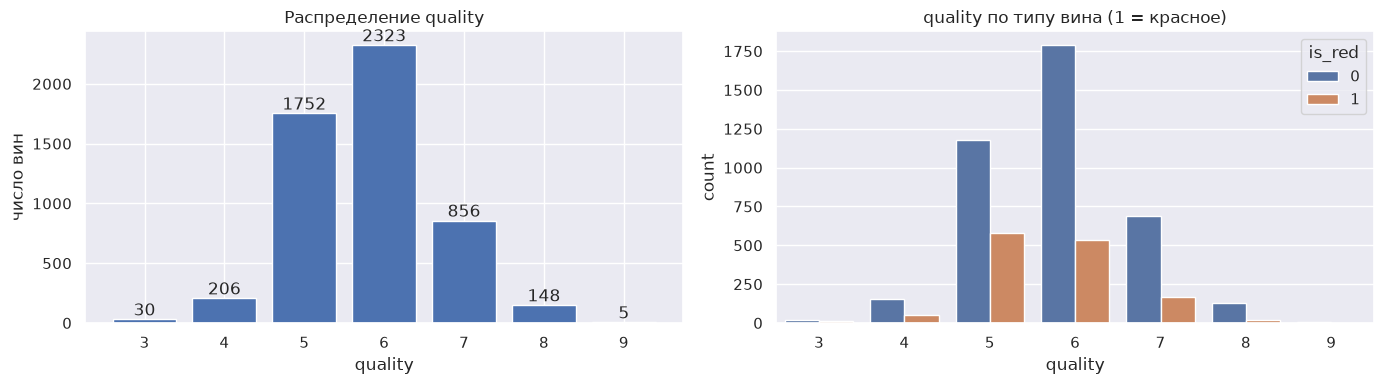

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
counts = df[TARGET].value_counts().sort_index()
axs[0].bar(counts.index, counts.values)
for q, c in counts.items():
    axs[0].text(q, c, str(c), ha="center", va="bottom")
axs[0].set_xlabel("quality"); axs[0].set_ylabel("число вин"); axs[0].set_title("Распределение quality")

sns.countplot(data=df, x=TARGET, hue="is_red", ax=axs[1])
axs[1].set_title("quality по типу вина (1 = красное)")
plt.tight_layout()

print((counts / len(df)).round(3))
print("mean = %.3f, median = %.1f, std = %.3f" % (df[TARGET].mean(), df[TARGET].median(), df[TARGET].std()))

Вывод:
- Оценки только от 3 до 9, и почти все вина (77%) получили 5 или 6. Оценок 3 всего 30, а 9 вообще 5 штук.
- Из-за этого модель скорее всего будет хорошо предсказывать средние вина и плохо очень плохие и очень хорошие.
- Стандартное отклонение quality = 0.88. Примерно такой RMSE и будет, если всегда предсказывать среднее. Чтобы получить < 0.70, модель должна реально что-то брать из признаков.

### Распределения признаков

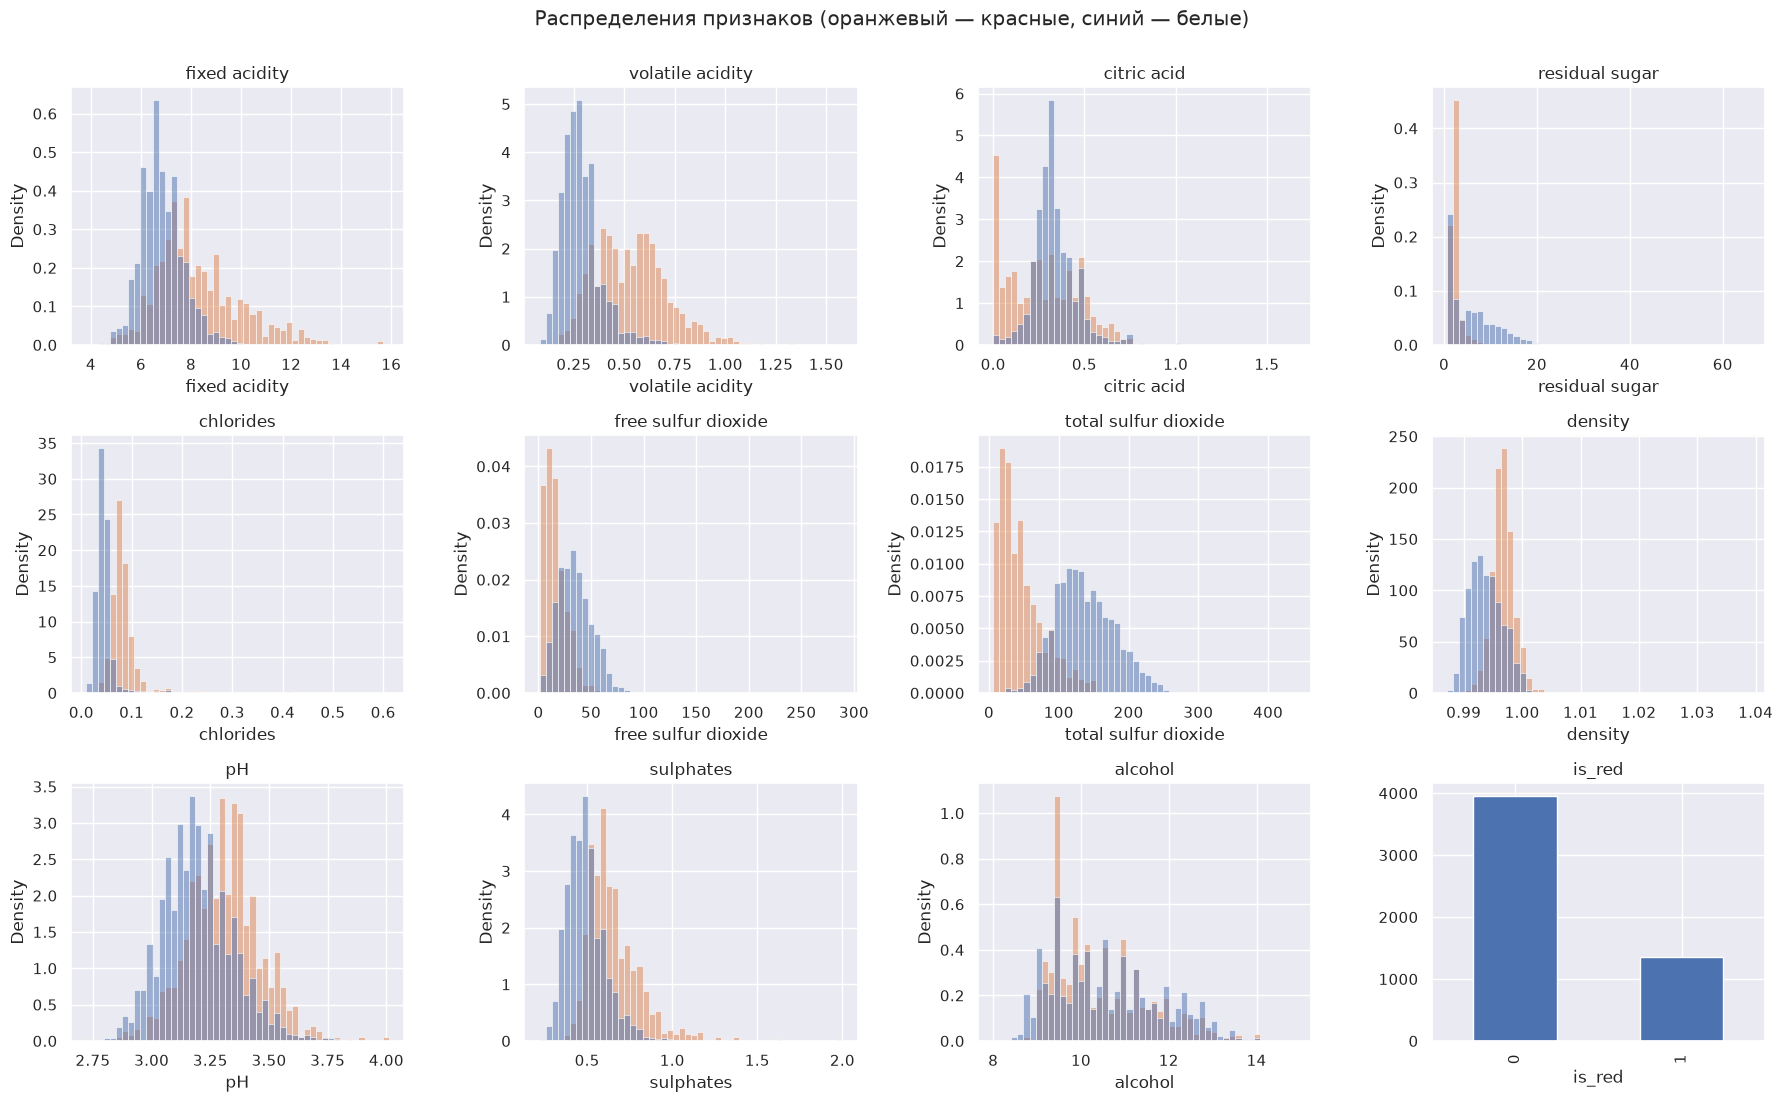

In [6]:
fig, axs = plt.subplots(3, 4, figsize=(18, 11))
for ax, col in zip(axs.ravel(), FEATURES):
    if col == "is_red":
        df[col].value_counts().plot.bar(ax=ax); ax.set_title(col); continue
    sns.histplot(data=df, x=col, hue="is_red", bins=50, stat="density", common_norm=False, ax=ax, legend=False)
    ax.set_title(col)
plt.suptitle("Распределения признаков (оранжевый — красные, синий — белые)", y=1.0)
plt.tight_layout()

У красных и белых вин распределения сильно разные. У белых намного больше сахара и диоксида серы, у красных выше летучая кислотность, хлориды и сульфаты. То есть одно и то же значение признака для красного и белого вина может значить разное. Поэтому `is_red` оставляю. Деревья смогут учитывать такие сочетания сами, а обычная линейная регрессия нет.

### Связь признаков с качеством

alcohol                 0.4694
density                -0.3264
volatile acidity       -0.2652
chlorides              -0.2021
is_red                 -0.1148
citric acid             0.0980
fixed acidity          -0.0801
residual sugar         -0.0568
free sulfur dioxide     0.0540
total sulfur dioxide   -0.0503
sulphates               0.0419
pH                      0.0397
Name: quality, dtype: float64

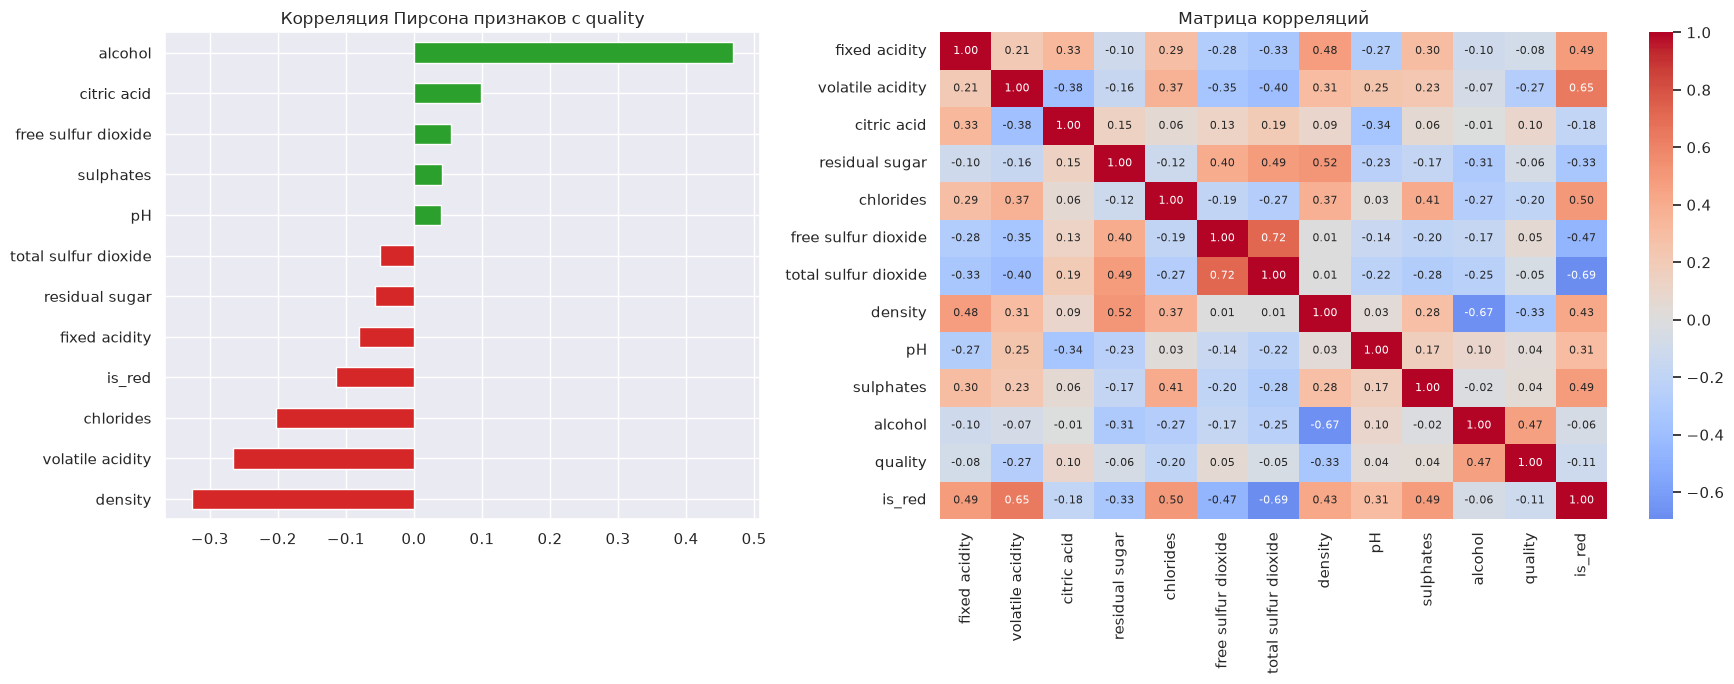

In [7]:
corr = df.corr()
target_corr = corr[TARGET].drop(TARGET).sort_values()

fig, axs = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [1, 1.4]})
target_corr.plot.barh(ax=axs[0], color=["tab:red" if v < 0 else "tab:green" for v in target_corr])
axs[0].set_title("Корреляция Пирсона признаков с quality")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axs[1], annot_kws={"size": 8})
axs[1].set_title("Матрица корреляций")
plt.tight_layout()
target_corr.sort_values(key=abs, ascending=False)

In [8]:
# спирмен - смотрим монотонную связь, не только линейную
spearman = df.corr(method="spearman")[TARGET].drop(TARGET)
pd.DataFrame({"pearson": corr[TARGET].drop(TARGET), "spearman": spearman}).sort_values("pearson", key=abs, ascending=False)

,pearson,spearman
alcohol,0.4694,0.4798
density,-0.3264,-0.3490
volatile acidity,-0.2652,-0.2514
chlorides,-0.2021,-0.3039
is_red,-0.1148,-0.1201
citric acid,0.0980,0.1165
fixed acidity,-0.0801,-0.1040
residual sugar,-0.0568,-0.0282
free sulfur dioxide,0.0540,0.0900
total sulfur dioxide,-0.0503,-0.0582


In [9]:
# корреляции отдельно для красных и белых
pd.DataFrame({
    "red": red.drop(columns="is_red").corr()[TARGET].drop(TARGET),
    "white": white.drop(columns="is_red").corr()[TARGET].drop(TARGET),
}).sort_values("red", key=abs, ascending=False)

,red,white
alcohol,0.4803,0.4629
volatile acidity,-0.3952,-0.1907
sulphates,0.2488,0.0532
citric acid,0.2281,0.0071
density,-0.1843,-0.3378
total sulfur dioxide,-0.1779,-0.1834
chlorides,-0.1310,-0.2177
fixed acidity,0.1190,-0.1246
pH,-0.0552,0.1238
free sulfur dioxide,-0.0505,0.0105


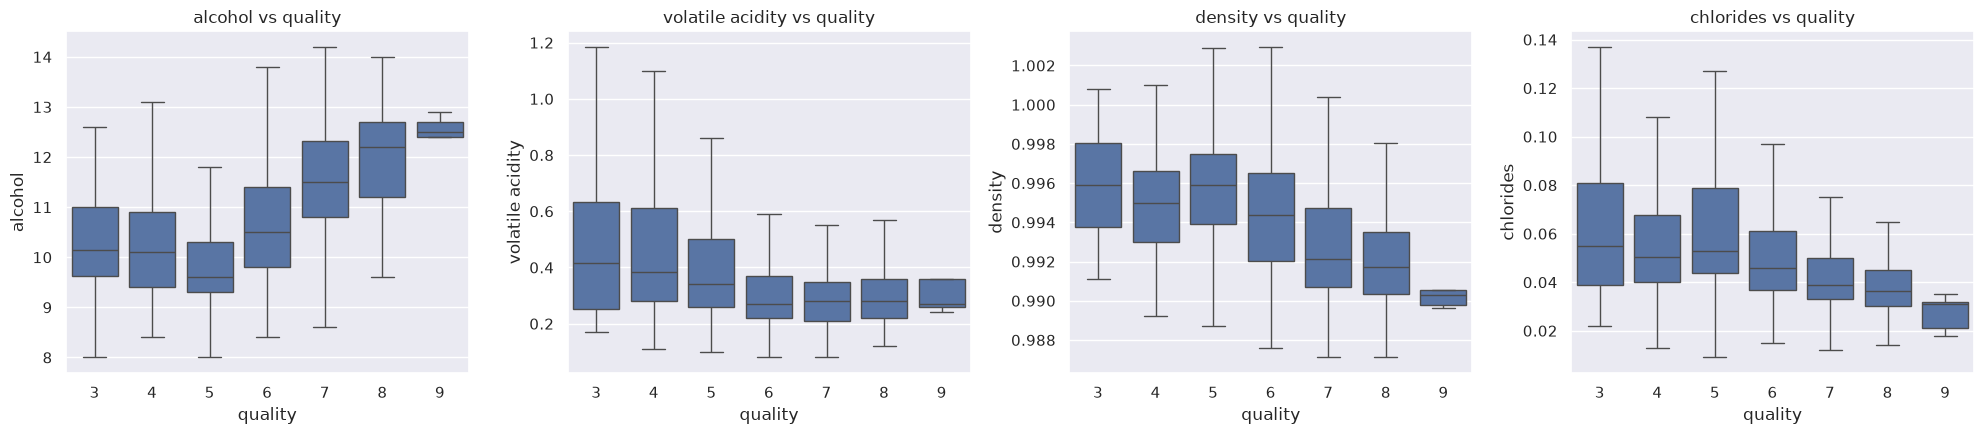

In [10]:
fig, axs = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, col in zip(axs, ["alcohol", "volatile acidity", "density", "chlorides"]):
    sns.boxplot(data=df, x=TARGET, y=col, ax=ax, showfliers=False)
    ax.set_title(f"{col} vs quality")
plt.tight_layout()

Выводы:

- `alcohol` - самый сильный признак (r = 0.47). На боксплоте видно, что чем выше оценка, тем больше алкоголя. Это главный признак для модели. Правда зависимость не совсем линейная: у оценок 3-5 алкоголь почти одинаковый, а рост начинается дальше.
- `density` (r = -0.33) коррелирует с качеством, но в основном через алкоголь: плотность сильно зависит от алкоголя (r = -0.67) и сахара (r = 0.52). Отдельно от них она почти ничего не добавляет. Для линейной модели это мультиколлинеарность, и её коэффициенты будет сложно трактовать.
- `volatile acidity` (r = -0.27) - это уксусная кислота, она портит вкус. У красных вин связь сильнее (r = -0.40), чем у белых.
- `chlorides` (r = -0.20): у Спирмена связь сильнее (-0.30), значит она монотонная, но не линейная или её портят выбросы.
- Остальные признаки по общей корреляции почти не связаны с качеством (|r| < 0.1). Но это не значит, что они бесполезные. Например у `sulphates` для красных r = 0.25, а для белых 0.05, и на общих данных это усредняется.
- Между собой сильно связаны `free` и `total sulfur dioxide` (0.72), `density` с `alcohol` и сахаром, `is_red` с `total sulfur dioxide` (-0.69).

Итог: одного сильного признака нет (максимум |r| = 0.47), связи слабые и местами нелинейные, плюс есть разница между красными и белыми. Поэтому думаю, что линейная регрессия будет лучше baseline, но не сильно, а лес и бустинг дадут результат заметно лучше. Признаки не удаляю, их всего 12.

## 2. Подготовка выборок

Делю 80/20: в train 4256 вин, в test 1064. Данных немного, поэтому большую часть отдаю на обучение.

Использую стратификацию по `quality`, чтобы доли всех оценок в train и test были одинаковые. Это важно из-за редких оценок: иначе, например, все девятки могли бы случайно попасть в одну выборку. `random_state=42`, чтобы результат повторялся.

Тест использую только в конце для оценки. Параметры моделей подбираю на кросс-валидации (5 фолдов) по train.

**Вопрос:** какие проблемы, если много раз проверять модели на одном тесте?

**Ответ:** если смотреть на результат на тесте и по нему менять модель (параметры, признаки, выбор модели), то модель постепенно подгоняется под эти конкретные 1064 объекта. Получается переобучение на тест: результат на нём выглядит лучше, чем будет на новых данных (на скрытой выборке). Плюс если перебрать много вариантов, какой-то из них может выиграть просто случайно. Поэтому для подбора нужна валидация или кросс-валидация, а тест только для финальной проверки.

In [11]:
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("train:", X_train.shape, " test:", X_test.shape)
pd.DataFrame({
    "train": y_train.value_counts(normalize=True).sort_index(),
    "test": y_test.value_counts(normalize=True).sort_index(),
}).round(4)

train: (4256, 12)  test: (1064, 12)


,train,test
quality,,
3,0.0056,0.0056
4,0.0388,0.0385
5,0.3294,0.3289
6,0.4366,0.4370
7,0.1609,0.1607
8,0.0277,0.0282
9,0.0009,0.0009


In [12]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_rmse(model):
    # средний RMSE на кросс-валидации по train
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
    return -scores.mean(), scores.std()

results = {}

def evaluate(name, y_pred):
    # оценка на тесте, для всех моделей одинаковая
    results[name] = {
        "RMSE": root_mean_squared_error(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
    }
    print(f"{name}: RMSE = {results[name]['RMSE']:.4f}, MAE = {results[name]['MAE']:.4f}")

## 3. Метрики

$$\text{MAE} = \frac{1}{n}\sum_{i=1}^n |y_i - \hat y_i|, \qquad \text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^n (y_i - \hat y_i)^2}$$

**Что показывает MAE?** Среднюю ошибку по модулю в баллах quality. Например MAE = 0.45 значит, что в среднем модель ошибается на 0.45 балла. Все ошибки входят с одинаковым весом.

**Что показывает RMSE?** Тоже ошибку в баллах, но перед усреднением ошибки возводятся в квадрат, поэтому большие ошибки весят больше.

**Почему RMSE сильнее реагирует на большие ошибки?** Из-за квадрата. Ошибка 2 даёт 4, а ошибка 0.5 даёт 0.25. Одна большая ошибка весит как много маленьких.

**Почему MAE и RMSE могут сильно отличаться?** RMSE всегда >= MAE. Если все ошибки примерно одинаковые, они почти равны. Если ошибки в основном маленькие, но есть несколько больших, RMSE сильно вырастет, а MAE почти нет. У нас как раз такие большие ошибки будут на редких винах (3, 4, 8, 9).

## 4. Baseline

Baseline - предсказываем всем одно число. Для RMSE лучшая константа это среднее (для MAE была бы медиана). Основная метрика у нас RMSE, поэтому беру среднее по train. Медиану тоже посчитал для сравнения.

In [13]:
const_mean = y_train.mean()
const_median = y_train.median()
print(f"Среднее quality на train = {const_mean:.4f}, медиана = {const_median}")

evaluate("Baseline (mean)", np.full(len(y_test), const_mean))
print(f"(для сравнения, константа-медиана: RMSE = {root_mean_squared_error(y_test, np.full(len(y_test), const_median)):.4f}, "
      f"MAE = {mean_absolute_error(y_test, np.full(len(y_test), const_median)):.4f})")

Среднее quality на train = 5.7953, медиана = 6.0
Baseline (mean): RMSE = 0.8801, MAE = 0.6948
(для сравнения, константа-медиана: RMSE = 0.9032, MAE = 0.6429)


Baseline даёт RMSE = 0.880, это почти std quality. Медиана (6) даёт MAE лучше, а RMSE хуже, как и должно быть по теории. Значит модель должна быть заметно лучше 0.88, а для порога надо уменьшить ошибку примерно на 20%.

## 5. Модели

### 5.1 Линейная регрессия

Делаю Pipeline: StandardScaler + LinearRegression.

**Нужно ли масштабирование?** На качество обычной линейной регрессии оно не влияет, предсказания будут те же. Но оно нужно, чтобы сравнивать коэффициенты. Без масштабирования коэффициент показывает изменение quality при изменении признака на 1 единицу, а 1 единица density это огромное изменение, а 1 мг/л диоксида серы - очень маленькое. После StandardScaler коэффициент показывает изменение quality при изменении признака на одно стандартное отклонение, и их уже можно сравнивать. Для Ridge/Lasso масштабирование нужно и для качества, иначе регуляризация штрафует признаки неравномерно.

In [14]:
lr_pipeline = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
print("LinearRegression CV RMSE = %.4f ± %.4f" % cv_rmse(lr_pipeline))

lr_pipeline.fit(X_train, y_train)
print("Train RMSE = %.4f" % root_mean_squared_error(y_train, lr_pipeline.predict(X_train)))
evaluate("Linear Regression", lr_pipeline.predict(X_test))

LinearRegression CV RMSE = 0.7327 ± 0.0202
Train RMSE = 0.7307
Linear Regression: RMSE = 0.7292, MAE = 0.5660


In [15]:
# коэффициенты без масштабирования для сравнения
lr_raw = LinearRegression().fit(X_train, y_train)

coefs = pd.DataFrame({
    "coef_raw": lr_raw.coef_,
    "coef_scaled": lr_pipeline.named_steps["model"].coef_,
    "feature_std": X_train.std().values,
}, index=FEATURES).sort_values("coef_scaled", key=abs, ascending=False)
coefs

,coef_raw,coef_scaled,feature_std
density,-94.7183,-0.2810,0.0030
alcohol,0.2314,0.2755,1.1907
residual sugar,0.0510,0.2268,4.4500
volatile acidity,-1.3258,-0.2209,0.1666
sulphates,0.8040,0.1174,0.1461
is_red,0.2604,0.1137,0.4368
free sulfur dioxide,0.0063,0.1118,17.8237
pH,0.6656,0.1067,0.1603
total sulfur dioxide,-0.0019,-0.1054,56.5538
fixed acidity,0.0731,0.0973,1.3315


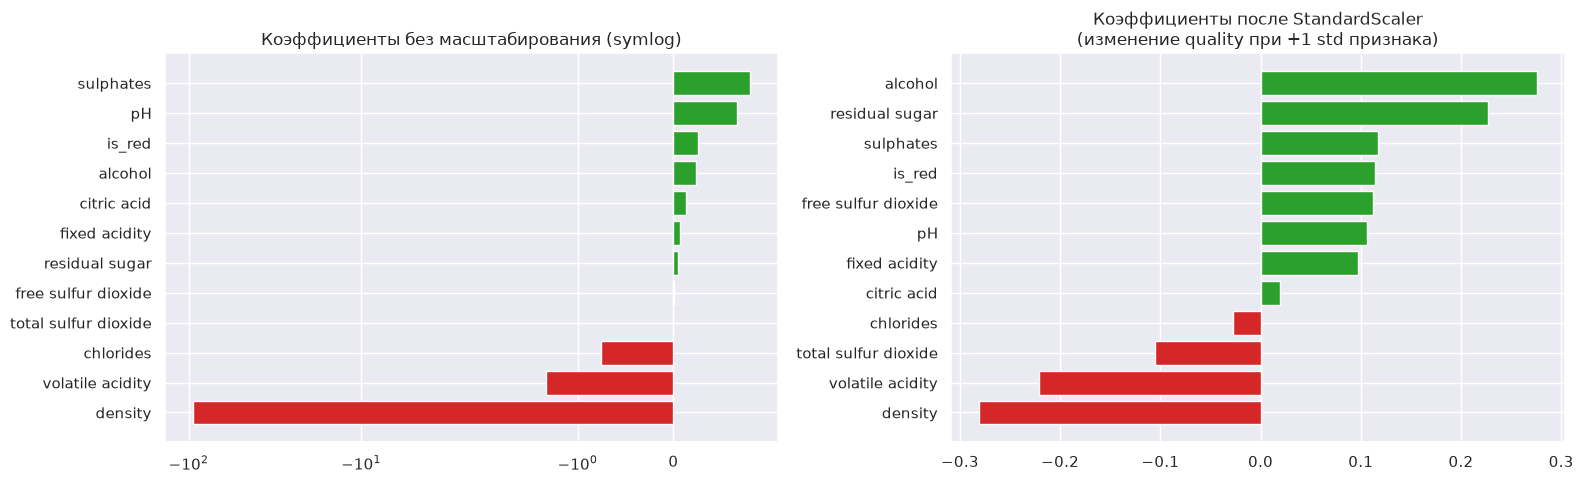

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5))
c_raw = coefs["coef_raw"].sort_values()
axs[0].barh(c_raw.index, c_raw.values, color=["tab:red" if v < 0 else "tab:green" for v in c_raw])
axs[0].set_xscale("symlog"); axs[0].set_title("Коэффициенты без масштабирования (symlog)")
c_sc = coefs["coef_scaled"].sort_values()
axs[1].barh(c_sc.index, c_sc.values, color=["tab:red" if v < 0 else "tab:green" for v in c_sc])
axs[1].set_title("Коэффициенты после StandardScaler\n(изменение quality при +1 std признака)")
plt.tight_layout()

In [17]:
# проверка: ridge с подбором alpha и модель без density
ridge = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("model", Ridge())]),
    {"model__alpha": np.logspace(-3, 3, 25)},
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1,
).fit(X_train, y_train)
print("Ridge: best alpha = %.3f, CV RMSE = %.4f" % (ridge.best_params_["model__alpha"], -ridge.best_score_))

no_density = [f for f in FEATURES if f != "density"]
lr_nd = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
nd_score = -cross_val_score(lr_nd, X_train[no_density], y_train, cv=cv, scoring="neg_root_mean_squared_error").mean()
print("LinearRegression без density: CV RMSE = %.4f" % nd_score)
lr_nd.fit(X_train[no_density], y_train)
pd.DataFrame({
    "с density": coefs["coef_scaled"],
    "без density": pd.Series(lr_nd.named_steps["model"].coef_, index=no_density),
}).sort_values("с density", key=abs, ascending=False)

Ridge: best alpha = 31.623, CV RMSE = 0.7324
LinearRegression без density: CV RMSE = 0.7346


,с density,без density
density,-0.2810,NaN
alcohol,0.2755,0.3978
residual sugar,0.2268,0.0648
volatile acidity,-0.2209,-0.2329
sulphates,0.1174,0.0986
is_red,0.1137,0.0272
free sulfur dioxide,0.1118,0.1227
pH,0.1067,0.0479
total sulfur dioxide,-0.1054,-0.1231
fixed acidity,0.0973,-0.0067


Что получилось:

- RMSE на тесте 0.729, у baseline 0.880. То есть модель что-то из признаков берёт (ошибка меньше примерно на 17%), но порог 0.70 не проходит.
- На train 0.731, на CV 0.733, на тесте 0.729, всё почти одинаковое. Значит переобучения нет, модель наоборот слишком простая (недообучение). Ridge с подобранным alpha даёт то же самое, так что дело не в регуляризации, а в том, что модель линейная.
- Без масштабирования коэффициент у density около -95, и кажется, что это самый важный признак. Но это просто из-за того, что std у density 0.003. После масштабирования он того же порядка, что остальные.
- После масштабирования самые большие коэффициенты: `density` (-0.28), `alcohol` (+0.28), `residual sugar` (+0.23), `volatile acidity` (-0.22), дальше `sulphates`, `is_red`, `free sulfur dioxide`.
- Странно, что у сахара большой вес, хотя в EDA он почти не коррелировал с качеством. Это из-за мультиколлинеарности: density зависит от алкоголя и сахара, и модель использует их вместе. Я проверил: если убрать density, CV RMSE почти не меняется (0.733 -> 0.735), вес сахара падает с 0.23 до 0.06, а вес алкоголя растёт с 0.28 до 0.40. Так что коэффициенты связанных признаков по отдельности трактовать нельзя.
- Что точно можно сказать (и это совпадает с EDA): больше алкоголя - выше оценка, больше летучей кислотности - ниже, сульфаты немного повышают.

### 5.2 Random Forest

Случайный лес - много глубоких деревьев, ответ это среднее по ним. Он может находить нелинейные зависимости и взаимодействия признаков, масштабирование ему не нужно. Параметры подбираю по кросс-валидации на train.

In [18]:
rf_search = GridSearchCV(
    RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    {"max_features": [0.33, 0.5, 1.0], "min_samples_leaf": [1, 2, 4]},
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=1,
).fit(X_train, y_train)
print("Лучшие параметры:", rf_search.best_params_, " CV RMSE = %.4f" % -rf_search.best_score_)
pd.DataFrame(rf_search.cv_results_)[["param_max_features", "param_min_samples_leaf", "mean_test_score"]] \
    .assign(cv_rmse=lambda d: -d.mean_test_score).drop(columns="mean_test_score").sort_values("cv_rmse")

Лучшие параметры: {'max_features': 0.33, 'min_samples_leaf': 1}  CV RMSE = 0.6869


,param_max_features,param_min_samples_leaf,cv_rmse
0,0.33,1,0.6869
1,0.33,2,0.6873
4,0.50,2,0.6894
3,0.50,1,0.6900
2,0.33,4,0.6916
5,0.50,4,0.6919
6,1.00,1,0.6934
7,1.00,2,0.6934
8,1.00,4,0.6951


In [19]:
rf = RandomForestRegressor(n_estimators=1000, random_state=RANDOM_STATE, n_jobs=-1, **rf_search.best_params_)
rf.fit(X_train, y_train)
print("Train RMSE = %.4f" % root_mean_squared_error(y_train, rf.predict(X_train)))
evaluate("Random Forest", rf.predict(X_test))

Train RMSE = 0.2506
Random Forest: RMSE = 0.6784, MAE = 0.5248


alcohol                 0.1799
density                 0.1090
volatile acidity        0.0989
free sulfur dioxide     0.0898
chlorides               0.0832
total sulfur dioxide    0.0817
sulphates               0.0776
residual sugar          0.0713
pH                      0.0708
citric acid             0.0696
fixed acidity           0.0639
is_red                  0.0044
dtype: float64

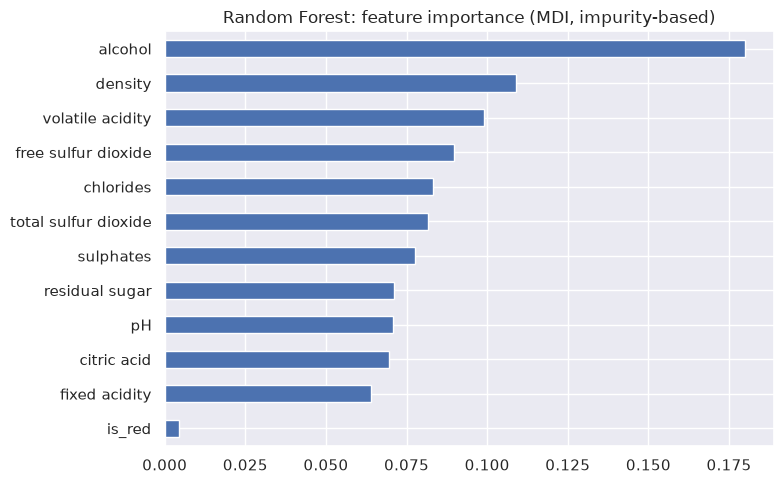

In [20]:
rf_imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
rf_imp.plot.barh(figsize=(8, 5), title="Random Forest: feature importance (MDI, impurity-based)")
plt.tight_layout()
rf_imp.sort_values(ascending=False)

RMSE на тесте 0.678 (на CV 0.687), порог пройден, и это заметно лучше линейной регрессии. На train RMSE 0.25, то есть деревья почти запоминают обучающую выборку, но из-за усреднения по 1000 деревьев на новых данных всё равно работает хорошо.

Важные признаки: `alcohol`, потом `density`, `volatile acidity`, `free sulfur dioxide`. Первые три совпадают с EDA. Что отличается от линейной регрессии:
- `free sulfur dioxide` у леса важнее. Скорее всего зависимость там не монотонная (плохо и когда SO2 мало, и когда много), а линейная модель такое не видит.
- `residual sugar` у леса средний, а в линейной модели большой вес был из-за связи с density.
- `density` высоко в основном потому, что заменяет alcohol. MDI делит важность между похожими признаками.
- `is_red` почти не важен, тип вина и так понятен по другим признакам (диоксид серы, хлориды, кислотность).

### 5.3 Gradient Boosting

Бустинг строит деревья по очереди, каждое следующее исправляет ошибки предыдущих. Сначала пробую параметры по умолчанию, потом подбираю по CV.

In [21]:
gb_default = GradientBoostingRegressor(random_state=RANDOM_STATE)
print("GB (default: 100 деревьев, depth=3, lr=0.1) CV RMSE = %.4f ± %.4f" % cv_rmse(gb_default))

GB (default: 100 деревьев, depth=3, lr=0.1) CV RMSE = 0.7066 ± 0.0124


In [22]:
gb_search = GridSearchCV(
    GradientBoostingRegressor(n_estimators=800, learning_rate=0.05, subsample=0.8, random_state=RANDOM_STATE),
    {"max_depth": [4, 6, 8], "min_samples_leaf": [1, 5]},
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1,
).fit(X_train, y_train)
print("Лучшие параметры:", gb_search.best_params_, " CV RMSE = %.4f" % -gb_search.best_score_)
pd.DataFrame(gb_search.cv_results_)[["param_max_depth", "param_min_samples_leaf", "mean_test_score"]] \
    .assign(cv_rmse=lambda d: -d.mean_test_score).drop(columns="mean_test_score").sort_values("cv_rmse")

Лучшие параметры: {'max_depth': 8, 'min_samples_leaf': 1}  CV RMSE = 0.6998


,param_max_depth,param_min_samples_leaf,cv_rmse
4,8,1,0.6998
5,8,5,0.7008
3,6,5,0.7025
1,4,5,0.7047
2,6,1,0.7060
0,4,1,0.7071


In [23]:
gb = gb_search.best_estimator_
print("Train RMSE = %.4f" % root_mean_squared_error(y_train, gb.predict(X_train)))
evaluate("Gradient Boosting", gb.predict(X_test))

Train RMSE = 0.0148
Gradient Boosting: RMSE = 0.7036, MAE = 0.5369


,Random Forest,Gradient Boosting
alcohol,0.1799,0.2260
density,0.1090,0.0671
volatile acidity,0.0989,0.1081
free sulfur dioxide,0.0898,0.0942
chlorides,0.0832,0.0717
total sulfur dioxide,0.0817,0.0837
sulphates,0.0776,0.0789
residual sugar,0.0713,0.0743
pH,0.0708,0.0744
citric acid,0.0696,0.0606


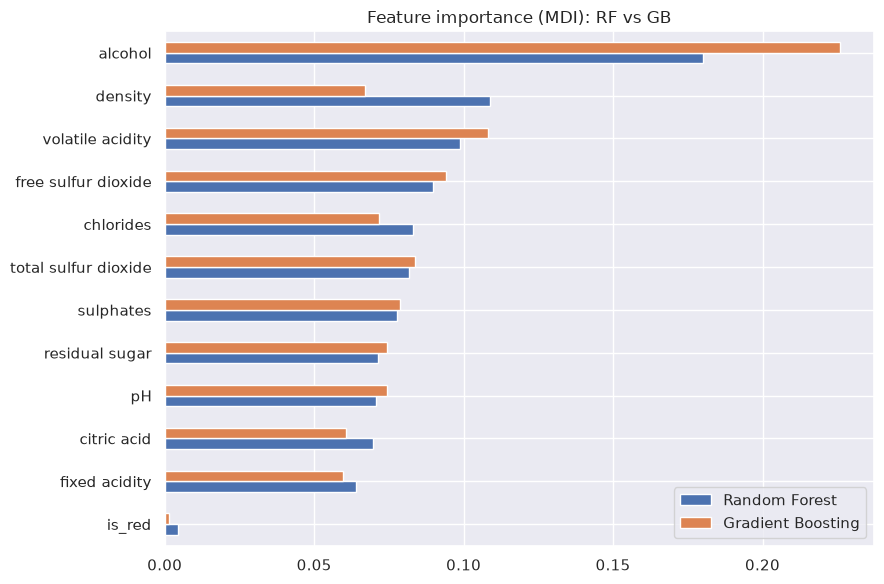

In [24]:
gb_imp = pd.Series(gb.feature_importances_, index=FEATURES)
imp = pd.DataFrame({"Random Forest": rf_imp, "Gradient Boosting": gb_imp}).sort_values("Random Forest")
imp.plot.barh(figsize=(9, 6), title="Feature importance (MDI): RF vs GB")
plt.tight_layout()
imp.sort_values("Random Forest", ascending=False)

- С параметрами по умолчанию (100 деревьев глубины 3) CV RMSE 0.71, это хуже леса, деревья слишком мелкие. После подбора (глубина 8, 800 деревьев, learning_rate 0.05, subsample 0.8) стало чуть лучше (CV 0.700), но всё равно хуже леса: на CV 0.700 против 0.687, на тесте RMSE 0.704 против 0.678, MAE 0.537 против 0.525. Порог 0.70 бустинг на тесте не прошёл, хоть и совсем немного.
- На train RMSE 0.015, то есть он почти запомнил train. Без дубликатов в тесте это уже не помогает, и разрыв между train и test большой, бустинг немного переобучен.
- Важность признаков у RF и GB похожая: на первом месте `alcohol`, дальше `volatile acidity` и `free sulfur dioxide`. У бустинга важность больше сосредоточена на alcohol. У леса она более равномерная, потому что в каждом сплите выбирается случайная часть признаков, и alcohol с density делят важность.

## 6. Сравнение моделей

Все модели учились на одном и том же train, параметры подбирались только по CV, проверка на одном и том же test.

In [25]:
cv_table = {
    "Baseline (mean)": np.nan,
    "Linear Regression": cv_rmse(lr_pipeline)[0],
    "Random Forest": cv_rmse(rf)[0],
    "Gradient Boosting": cv_rmse(gb)[0],
}
summary = pd.DataFrame(results).T
summary["CV RMSE (train)"] = pd.Series(cv_table)
summary["RMSE / MAE"] = summary["RMSE"] / summary["MAE"]
summary["улучшение RMSE vs baseline"] = 1 - summary["RMSE"] / summary.loc["Baseline (mean)", "RMSE"]
summary["RMSE < 0.70"] = summary["RMSE"] < 0.70
summary.index.name = "Модель"
summary

,RMSE,MAE,CV RMSE (train),RMSE / MAE,улучшение RMSE vs baseline,RMSE < 0.70
Модель,,,,,,
Baseline (mean),0.8801,0.6948,NaN,1.2667,0.0000,False
Linear Regression,0.7292,0.5660,0.7327,1.2884,0.1714,False
Random Forest,0.6784,0.5248,0.6868,1.2927,0.2291,True
Gradient Boosting,0.7036,0.5369,0.6998,1.3106,0.2006,False


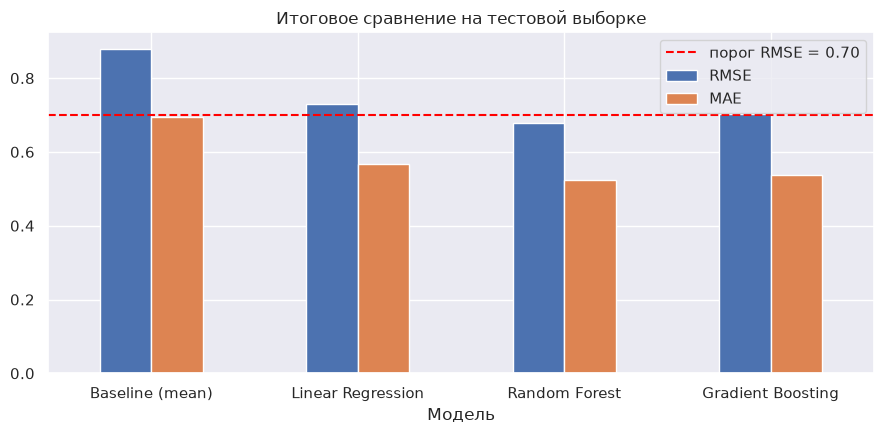

In [26]:
ax = summary[["RMSE", "MAE"]].plot.bar(figsize=(9, 4.5), rot=0)
ax.axhline(0.70, color="red", ls="--", label="порог RMSE = 0.70")
ax.legend(); ax.set_title("Итоговое сравнение на тестовой выборке")
plt.tight_layout()

**Какие модели лучше baseline?** Все три. Порог 0.70 прошёл только лес. Бустинг совсем немного не дотянул (0.704), линейная регрессия тоже не прошла. CV и тест у всех моделей близки, так что это не случайность разбиения.

**Почему деревья лучше линейной регрессии:**
1. Зависимости нелинейные: у alcohol рост начинается только после 5, а у free sulfur dioxide зависимость вообще не монотонная.
2. Есть взаимодействия признаков, например sulphates и volatile acidity важнее для красных. Линейная модель такое без ручных признаков не учитывает.
3. Выбросы и скошенные распределения мешают линейной модели, а деревьям всё равно, они работают с порогами.
4. Мультиколлинеарность (density, alcohol, сахар) мешает линейной модели, а деревьям нет.

**RF и GB:** лес немного лучше. Лес строит деревья независимо и усредняет, это уменьшает разброс, и он хорошо работает почти без настройки. Бустинг уменьшает ошибку постепенно, без подбора параметров заметно хуже, а с глубокими деревьями почти запоминает train. Скорее всего у обеих моделей есть предел, потому что оценки ставят люди, а часть того, что влияет на оценку (аромат, сорт и т.д.), в данных просто нет. Дубликаты удалены, поэтому одинаковых вин в train и test нет и результат на тесте честный.

**RMSE/MAE:** у baseline 1.27, у линейной 1.29, у леса 1.29, у бустинга 1.31, то есть почти одинаково. Деревья уменьшили ошибки примерно равномерно, а большие ошибки на редких винах (3, 4, 8, 9) остались у всех моделей, поэтому RMSE везде заметно больше MAE.

## 7. Feature importance

Встроенная важность у деревьев (MDI) считается на train и делит важность между похожими признаками. Поэтому дополнительно считаю permutation importance на тесте: перемешиваю один признак и смотрю, насколько вырос RMSE. Так можно сравнить все три модели, включая линейную.

,Linear Regression,Random Forest,Gradient Boosting
alcohol,0.0955,0.1162,0.1341
volatile acidity,0.0748,0.0525,0.0650
free sulfur dioxide,0.0194,0.0491,0.0678
sulphates,0.0162,0.0241,0.0291
density,0.0996,0.0224,0.0208
total sulfur dioxide,0.0109,0.0221,0.0454
chlorides,0.0027,0.0168,0.0166
citric acid,0.0007,0.0150,0.0137
residual sugar,0.0848,0.0148,0.0348
pH,0.0074,0.0098,0.0162


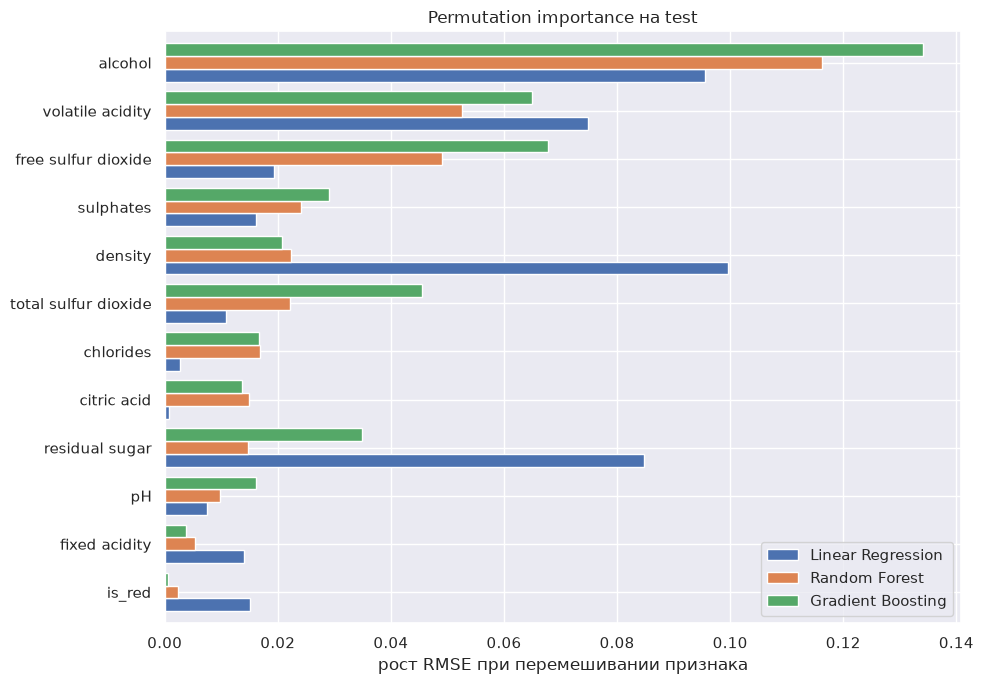

In [27]:
perm = {}
for name, model in [("Linear Regression", lr_pipeline), ("Random Forest", rf), ("Gradient Boosting", gb)]:
    r = permutation_importance(model, X_test, y_test, n_repeats=15, random_state=RANDOM_STATE,
                               scoring="neg_root_mean_squared_error", n_jobs=-1)
    perm[name] = pd.Series(r.importances_mean, index=FEATURES)
perm = pd.DataFrame(perm)

order = perm["Random Forest"].sort_values().index
perm.loc[order].plot.barh(figsize=(10, 7), width=0.8)
plt.xlabel("рост RMSE при перемешивании признака")
plt.title("Permutation importance на test")
plt.tight_layout()
perm.loc[order[::-1]]

In [28]:
# ранги важности (1 - самый важный)
ranks = pd.DataFrame({
    "|corr| с quality (EDA)": target_corr.abs().rank(ascending=False),
    "|coef| LR (scaled)": coefs["coef_scaled"].abs().rank(ascending=False),
    "RF MDI": rf_imp.rank(ascending=False),
    "GB MDI": gb_imp.rank(ascending=False),
    "RF permutation": perm["Random Forest"].rank(ascending=False),
    "GB permutation": perm["Gradient Boosting"].rank(ascending=False),
}).astype(int).sort_values("RF permutation")
ranks

,|corr| с quality (EDA),|coef| LR (scaled),RF MDI,GB MDI,RF permutation,GB permutation
alcohol,1,2,1,1,1,1
volatile acidity,3,4,3,2,2,3
free sulfur dioxide,9,7,4,3,3,2
sulphates,11,5,7,5,4,6
density,2,1,2,9,5,7
total sulfur dioxide,10,9,6,4,6,4
chlorides,4,11,5,8,7,8
citric acid,6,12,10,10,8,10
residual sugar,8,3,8,7,9,5
pH,12,8,9,6,10,9


Выводы:
1. `alcohol` на первом месте почти везде: по корреляции, по MDI и permutation у обоих ансамблей.
2. `volatile acidity` почти везде в топ-3, как и было в EDA.
3. `free sulfur dioxide` у деревьев в топ-4, хотя корреляция почти 0. Зависимость не монотонная, и корреляция её не видит.
4. `density` у леса по MDI на 2 месте, а у бустинга по MDI только на 9 и по permutation на 7. Если её перемешать, модель берёт ту же информацию из alcohol и сахара. У линейной регрессии у density permutation importance самая большая (даже больше alcohol), а сахар почти как alcohol, потому что она строит предсказание на их сочетании.
5. `is_red` почти ни на что не влияет.
6. `sulphates` и `total sulfur dioxide` у деревьев на 4-7 местах, хотя общая корреляция около 0.05. Для sulphates это понятно из EDA: у красных он связан с качеством, у белых нет.
7. Меньше всего важны `fixed acidity`, `pH`, `citric acid`.

RF и GB между сходятся гораздо лучше, чем с линейной регрессией.

**Вопрос:** можно ли по feature importance сказать, что изменение признака является причиной изменения качества вина?

**Ответ:** нет. Важность показывает только то, что модель использует этот признак, то есть что есть связь в данных. Это не значит, что есть причина. Например, у хорошего вина может быть больше алкоголя, потому что виноград был спелый и год хороший. Это влияет и на алкоголь, и на качество, но если просто добавить спирт в плохое вино, оно лучше не станет. Ещё density важна для модели, но она просто отражает алкоголь и сахар. И важность зависит от модели и способа подсчёта (MDI и permutation дают разный порядок). Чтобы говорить о причинах, нужен эксперимент, а у нас просто наблюдения.

## 8. Анализ ошибок

Лучшую модель выбираю по CV RMSE (не по тесту), это Random Forest. Ошибки смотрю на тесте.

In [29]:
best_name = summary["CV RMSE (train)"].idxmin()
best_model = {"Linear Regression": lr_pipeline, "Random Forest": rf, "Gradient Boosting": gb}[best_name]
print("Лучшая модель по CV:", best_name)

err = X_test.copy()
err["quality"] = y_test
err["pred"] = best_model.predict(X_test)
err["error"] = err["pred"] - err["quality"]          # >0 — переоценили, <0 — недооценили
err["abs_error"] = err["error"].abs()
err["error"].describe()

Лучшая модель по CV: Random Forest


count    1064.0000
mean       -0.0223
std         0.6784
min        -3.4650
25%        -0.4888
50%         0.0380
75%         0.3820
max         2.6190
Name: error, dtype: float64

Доля ошибок |e| < 0.5: 0.565
Доля ошибок |e| < 1.0: 0.878
Доля верных после округления: 0.565


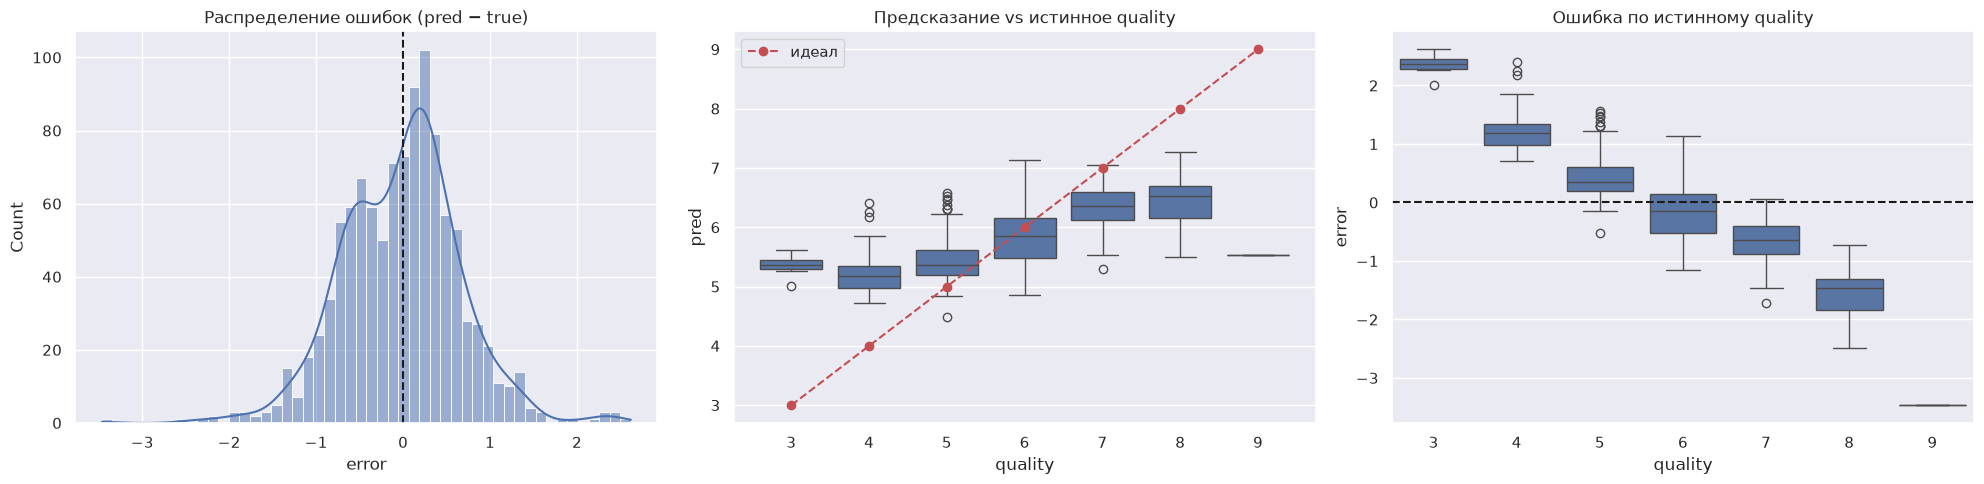

In [30]:
fig, axs = plt.subplots(1, 3, figsize=(20, 5))
sns.histplot(err["error"], bins=50, kde=True, ax=axs[0])
axs[0].axvline(0, color="k", ls="--"); axs[0].set_title("Распределение ошибок (pred − true)")

sns.boxplot(data=err, x="quality", y="pred", ax=axs[1])
axs[1].plot(range(err["quality"].nunique()), sorted(err["quality"].unique()), "r--o", label="идеал")
axs[1].legend(); axs[1].set_title("Предсказание vs истинное quality")

sns.boxplot(data=err, x="quality", y="error", ax=axs[2])
axs[2].axhline(0, color="k", ls="--"); axs[2].set_title("Ошибка по истинному quality")
plt.tight_layout()

print("Доля ошибок |e| < 0.5:", (err["abs_error"] < 0.5).mean().round(3))
print("Доля ошибок |e| < 1.0:", (err["abs_error"] < 1.0).mean().round(3))
print("Доля верных после округления:", (err["pred"].round() == err["quality"]).mean().round(3))

In [31]:
by_q = err.groupby("quality").agg(
    n=("error", "size"),
    mean_pred=("pred", "mean"),
    bias=("error", "mean"),
    MAE=("abs_error", "mean"),
    RMSE=("error", lambda e: np.sqrt(np.mean(e ** 2))),
)
by_q["доля в train"] = y_train.value_counts(normalize=True).reindex(by_q.index).round(4)
by_q

,n,mean_pred,bias,MAE,RMSE,доля в train
quality,,,,,,
3,6,5.3508,2.3508,2.3508,2.3583,0.0056
4,41,5.2292,1.2292,1.2292,1.2857,0.0388
5,350,5.4264,0.4264,0.4325,0.5371,0.3294
6,465,5.8408,-0.1592,0.3848,0.4670,0.4366
7,171,6.3359,-0.6641,0.6651,0.7525,0.1609
8,30,6.4543,-1.5457,1.5457,1.6062,0.0277
9,1,5.5350,-3.4650,3.4650,3.4650,0.0009


In [32]:
# самые большие ошибки
worst = err.sort_values("abs_error", ascending=False).head(10)
worst[["is_red", "alcohol", "volatile acidity", "free sulfur dioxide", "sulphates", "density",
       "residual sugar", "quality", "pred", "error"]]

,is_red,alcohol,volatile acidity,free sulfur dioxide,sulphates,density,residual sugar,quality,pred,error
2012,0,10.4,0.270,28.0,0.46,0.9970,10.60,9,5.535,-3.465
1982,0,12.6,0.390,5.0,0.37,0.9915,4.60,3,5.619,2.619
2549,0,10.5,0.220,12.0,0.38,0.9944,6.80,8,5.504,-2.496
1571,0,9.8,0.260,41.0,0.50,0.9980,16.20,3,5.468,2.468
4984,0,11.5,0.260,75.0,0.38,0.9902,2.60,4,6.403,2.403
2783,0,9.4,0.250,118.5,0.63,0.9949,1.55,3,5.387,2.387
1165,1,9.8,0.815,16.0,0.51,0.9947,1.20,3,5.356,2.356
3881,0,12.5,0.530,6.0,0.50,0.9912,6.10,8,5.648,-2.352
1245,1,9.7,0.980,20.0,0.55,0.9970,2.10,3,5.268,2.268
4158,0,12.9,0.640,18.0,0.60,0.9892,1.20,4,6.254,2.254


In [33]:
# сравниваю с медианой train для настоящей и предсказанной оценки
train_full = X_train.assign(quality=y_train)
key = ["alcohol", "volatile acidity", "free sulfur dioxide", "sulphates", "residual sugar", "chlorides"]
rows = []
for idx, r in worst.head(5).iterrows():
    same = train_full[(train_full.quality == r.quality) & (train_full.is_red == r.is_red)]
    pred_cls = train_full[(train_full.quality == round(r.pred)) & (train_full.is_red == r.is_red)]
    rows.append(pd.concat([
        r[key].rename(f"объект {idx} (true={r.quality}, pred={r.pred:.2f})"),
        same[key].median().rename(f"  медиана train: quality={r.quality}, n={len(same)}"),
        pred_cls[key].median().rename(f"  медиана train: quality={round(r.pred)}"),
    ], axis=1).T)
pd.concat(rows)

,alcohol,volatile acidity,free sulfur dioxide,sulphates,residual sugar,chlorides
"объект 2012 (true=9.0, pred=5.54)",10.4,0.27,28.0,0.460,10.6,0.035
"медиана train: quality=9.0, n=4",12.6,0.31,29.0,0.450,2.1,0.026
медиана train: quality=6,10.5,0.25,33.0,0.480,4.8,0.042
"объект 1982 (true=3.0, pred=5.62)",12.6,0.39,5.0,0.370,4.6,0.022
"медиана train: quality=3.0, n=16",10.5,0.26,33.5,0.435,4.3,0.041
медиана train: quality=6,10.5,0.25,33.0,0.480,4.8,0.042
"объект 2549 (true=8.0, pred=5.50)",10.5,0.22,12.0,0.380,6.8,0.034
"медиана train: quality=8.0, n=101",12.2,0.28,34.0,0.480,3.8,0.035
медиана train: quality=6,10.5,0.25,33.0,0.480,4.8,0.042
"объект 1571 (true=3.0, pred=5.47)",9.8,0.26,41.0,0.500,16.2,0.074


In [34]:
# есть ли в train точно такие же вина
dup_cols = FEATURES
merged = worst.reset_index().merge(train_full, on=dup_cols, how="left", suffixes=("", "_train"))
merged[["index", "quality", "pred", "quality_train"]].dropna()

,index,quality,pred,quality_train


Выводы:

- Ошибки распределены почти симметрично около нуля (средняя -0.02), но есть хвосты. 57% предсказаний ошибаются меньше чем на 0.5, 88% меньше чем на 1, максимальная ошибка 3.5 (на единственном вине с оценкой 9).
- Для оценки 6 RMSE 0.47, для 5 - 0.54, тут всё нормально. А крайние оценки модель сдвигает к середине: вина с оценкой 3 в среднем получают 5.35, с оценкой 4 - 5.23, с оценкой 8 - 6.45, единственное вино с 9 получило 5.54. Ниже 5 и выше 7 модель почти не предсказывает.
- Самые большие ошибки все на редких оценках (3, 4, 8, 9). Разобрал несколько:
  - 2012 (белое, оценка 9, предсказано 5.5): алкоголь 10.4 (у девяток в train обычно 12.6) и много сахара (10.6 против 2.1). По химии это типичное вино на 6. Девяток в train всего 4, модели не на чем научиться.
  - 1982 (белое, оценка 3, предсказано 5.6): алкоголь 12.6, намного больше, чем обычно у оценки 3 (10.5). Подозрительно только очень мало свободного SO2 (5, обычно около 34), может вино окислилось. Но белых вин с оценкой 3 в train всего 16.
  - 2549 (белое, оценка 8, предсказано 5.5): по признакам обычное вино на 6, алкоголь 10.5 (у восьмёрок обычно 12.2). Чем оно понравилось экспертам, по этим данным не понять.
  - 1571 (оценка 3): много сахара (16.2), но по алкоголю и кислотности оно как среднее вино на 5. Таких примеров слишком мало, чтобы модель это выучила.
  - 4984 (белое, оценка 4, предсказано 6.4): алкоголь 11.5 и летучая кислотность 0.26, это как у хорошего вина, а не на 4. Выделяется только много свободного SO2 (75 против 18).

  То есть у этих вин признаки больше похожи на предсказанный класс, чем на настоящий. Скорее всего на оценку повлияло то, чего нет в данных (аромат, сорт, выдержка, бренд), или просто субъективность экспертов. Дубликаты удалены ещё в начале, и вин с такими же признаками в train нет (последняя таблица пустая), так что дело не в копиях с другой оценкой.

**Вопрос:** почему модель хуже предсказывает редкие значения quality?

**Ответ:**
1. Их очень мало в train, и в листьях деревьев они смешиваются с пятёрками и шестёрками.
2. Модель минимизирует средний квадрат ошибки, а он в основном зависит от частых оценок 5 и 6. Поэтому модели выгоднее хорошо угадывать их, а предсказания тянутся к среднему.
3. По химии крайние классы плохо отличаются от средних (самая большая корреляция всего 0.44).
4. Оценка это медиана нескольких экспертов, и крайние значения у неё встречаются редко.

Что можно попробовать: давать редким классам больший вес, отдельные модели для красного и белого, растягивать предсказания после обучения. Но скорее всего это немного ухудшит RMSE на обычных винах.

## 9. Итог

| Модель | RMSE (test) | MAE (test) |
|---|---|---|
| Baseline (mean) | 0.8801 | 0.6948 |
| Linear Regression | 0.7292 | 0.5660 |
| Random Forest | 0.6784 | 0.5248 |
| Gradient Boosting | 0.7036 | 0.5369 |

- Полные дубликаты (1177 строк) удалены в самом начале, поэтому одинаковых вин в train и test нет.
- Baseline (среднее по train) даёт RMSE 0.88.
- Линейная регрессия лучше baseline примерно на 17%, но порог 0.70 не проходит, потому что модель линейная.
- Порог проходит только Random Forest (RMSE 0.68). Бустинг совсем немного не дотянул (0.704). Деревья лучше линейной модели, потому что ловят нелинейности и взаимодействия признаков. Лучшая по CV модель - Random Forest, её и беру как финальную.
- Главные признаки: `alcohol` и `volatile acidity`, для деревьев ещё `free sulfur dioxide`. Но это связь, а не причина.
- Больше всего модель ошибается на редких оценках (3-4 и 8-9), она сдвигает их к середине.

In [35]:
# финальная модель: обучаю лучшую модель на всех данных
# на вход DataFrame с 11 признаками и is_red (1 - красное, 0 - белое)
final_model = best_model.__class__(**best_model.get_params()).fit(X, y)

def predict_quality(data: pd.DataFrame) -> np.ndarray:
    data = data.copy()
    if "is_red" not in data.columns and "type" in data.columns:
        data["is_red"] = (data["type"].astype(str).str.lower() == "red").astype(int)
    return final_model.predict(data[FEATURES])

predict_quality(X_test.head())

array([5.129, 6.148, 6.044, 6.77 , 5.13 ])